# Imports and preprocessing

In [1]:
import pickle

import matplotlib.pyplot as plt
import matplotlib
import os
import numpy as np
from align_toolbox.plotting.plotting_structure import combine_experiments
from align_toolbox.plotting.utils_plotting import save_figure
from align_toolbox.plotting.boxplots import boxplot, boxplot_larval_stage, violinplot
from align_toolbox.plotting.proportions import (
    plot_correlation,
    plot_continuous_deviation_from_model,
    plot_correlation_at_ecdysis,
    plot_normalized_proportions_at_ecdysis,
    plot_model_comparison_at_ecdysis,
    plot_deviation_from_model_at_ecdysis,
    plot_deviation_from_model_development_percentage,
    compute_deviation_from_model_at_ecdysis,
    compute_deviation_from_model_development_percentage,
)

from align_toolbox.plotting.utils_data_processing import (
    transform_series,
    compute_growth_rate,
    rescale,
    rescale_without_flattening,
    combine_series,
    smooth_series,
    smooth_and_rescale_series,
    detrend_rescaled_series_population_mean,
)

from align_toolbox.plotting.heterogeneity import (
    plot_cv_at_ecdysis,
    plot_std_at_ecdysis,
    plot_cv_development_percentage,
    plot_cv_rescaled_data,
)

from align_toolbox.plotting.curves import (
    plot_aggregated_series,
)

import warnings
import bottleneck as bn

import shutil
from pathlib import Path


# Configure warnings
warnings.filterwarnings("once")

In [2]:
filemap_paths = [
    "/mnt/towbin.data/shared/kstojanovski/20240202_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240202_171239_051/analysis_sacha/report/analysis_filemap_annotated.csv",
    "/mnt/towbin.data/shared/kstojanovski/20240212_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240212_164059_429/analysis_sacha/report/analysis_filemap_annotated.csv",
]

conditions_paths = [
    "/mnt/towbin.data/shared/kstojanovski/20240202_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240202_171239_051/doc/conditions.yaml",
    "/mnt/towbin.data/shared/kstojanovski/20240212_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240212_164059_429/doc/conditions.yaml",
]

organ_channels = [{'body': 'ch2', 'pharynx' : 'ch1'}]
# 

backup_path = "/path/to/backup/directory"
backup = False

In [3]:
conditions_struct = combine_experiments(filemap_paths, conditions_paths, organ_channels=organ_channels, recompute_values_at_molt=False)

File not found: /mnt/towbin.data/shared/kstojanovski/20240202_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240202_171239_051/analysis_sacha/report/analysis_filemap_annotated.csv, trying /mnt/towbin.data/shared/kstojanovski/20240202_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240202_171239_051/analysis_sacha/report/analysis_filemap_annotated.parquet instead.
File not found: /mnt/towbin.data/shared/kstojanovski/20240212_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240212_164059_429/analysis_sacha/report/analysis_filemap_annotated.csv, trying /mnt/towbin.data/shared/kstojanovski/20240212_Orca_10x_yap-1del_col-10-tir_wBT160-186-310-337-380-393_25C_20240212_164059_429/analysis_sacha/report/analysis_filemap_annotated.parquet instead.
Could not concatenate description: zero-dimensional arrays cannot be concatenated
Could not concatenate condition_id: zero-dimensional arrays cannot be concatenated
Could not concatenate description: zero-dimen

In [4]:
notebook_backup_path = os.path.join(backup_path, "notebook")

# backup the conditions struct
if backup:
    os.makedirs(backup_path, exist_ok=True)
    os.makedirs(notebook_backup_path, exist_ok=True)
    with open(os.path.join(notebook_backup_path, "conditions_struct.pkl"), "wb") as f:
        pickle.dump(conditions_struct, f)

    nb_path = Path(globals().get("__vsc_ipynb_file__", ""))
    if not nb_path.is_file():
        candidates = sorted(Path.cwd().glob("*.ipynb"), key=lambda p: p.stat().st_mtime, reverse=True)
        nb_path = candidates[0] if candidates else None

    if nb_path is not None:
        shutil.copy2(nb_path, notebook_backup_path)
    else:
        print("No notebook file found to back up.")


In [5]:
for condition in conditions_struct:
    print(f"Condition: {condition['condition_id'], {condition['description']}}, Number of individuals: {condition['ecdysis_time_step'].shape[0]}")

Condition: (0, {'no TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 58
Condition: (1, {'col-10:TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 55
Condition: (2, {'yap-1 (tm1416), no TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 79
Condition: (3, {'yap-1 (tm1416), col-10:TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 76
Condition: (4, {'yap-1 (abt7), no TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 99
Condition: (5, {'yap-1 (abt7), col-10:TIR, raga-1:AID, 500uM IAA'}), Number of individuals: 155


In [6]:
# change figure size to your liking
plt.rcParams['figure.figsize'] = [12, 10]

# make lines thicker
plt.rcParams['lines.linewidth'] = 2

# make font size bigger
plt.rcParams.update({'font.size': 24})

plt.rcParams['figure.constrained_layout.use'] = True

# ensure fonts are saved as text in svg files
plt.rcParams['svg.fonttype'] = 'none'

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

plt.rcParams.update({
    "pgf.preamble": r"\usepackage{arev}\n\usepackage[T1]{fontenc}"
})

In [15]:
# define colors for each condition
colors = {
    0: '#6BAED6',  # light blue
    1: '#08519C',  # dark blue
    4: '#FDAE6B',  # light orange
    5: '#D94801',  # dark orange
}

In [8]:
# rescale some series for plotting later
rescale_n_points = 100

conditions_struct = rescale(conditions_struct, 'body_seg_str_volume', 'body_seg_str_volume_rescaled', n_points=rescale_n_points)
conditions_struct = rescale(conditions_struct, 'body_seg_str_length', 'body_seg_str_length_rescaled', n_points=rescale_n_points)
conditions_struct = rescale(conditions_struct, 'pharynx_seg_str_volume', 'pharynx_seg_str_volume_rescaled', n_points=rescale_n_points)
conditions_struct = rescale(conditions_struct, 'pharynx_seg_str_length', 'pharynx_seg_str_length_rescaled', n_points=rescale_n_points)

# yap-1 mutant's growth gets slowed down more under col-10:TIR raga-1:AID

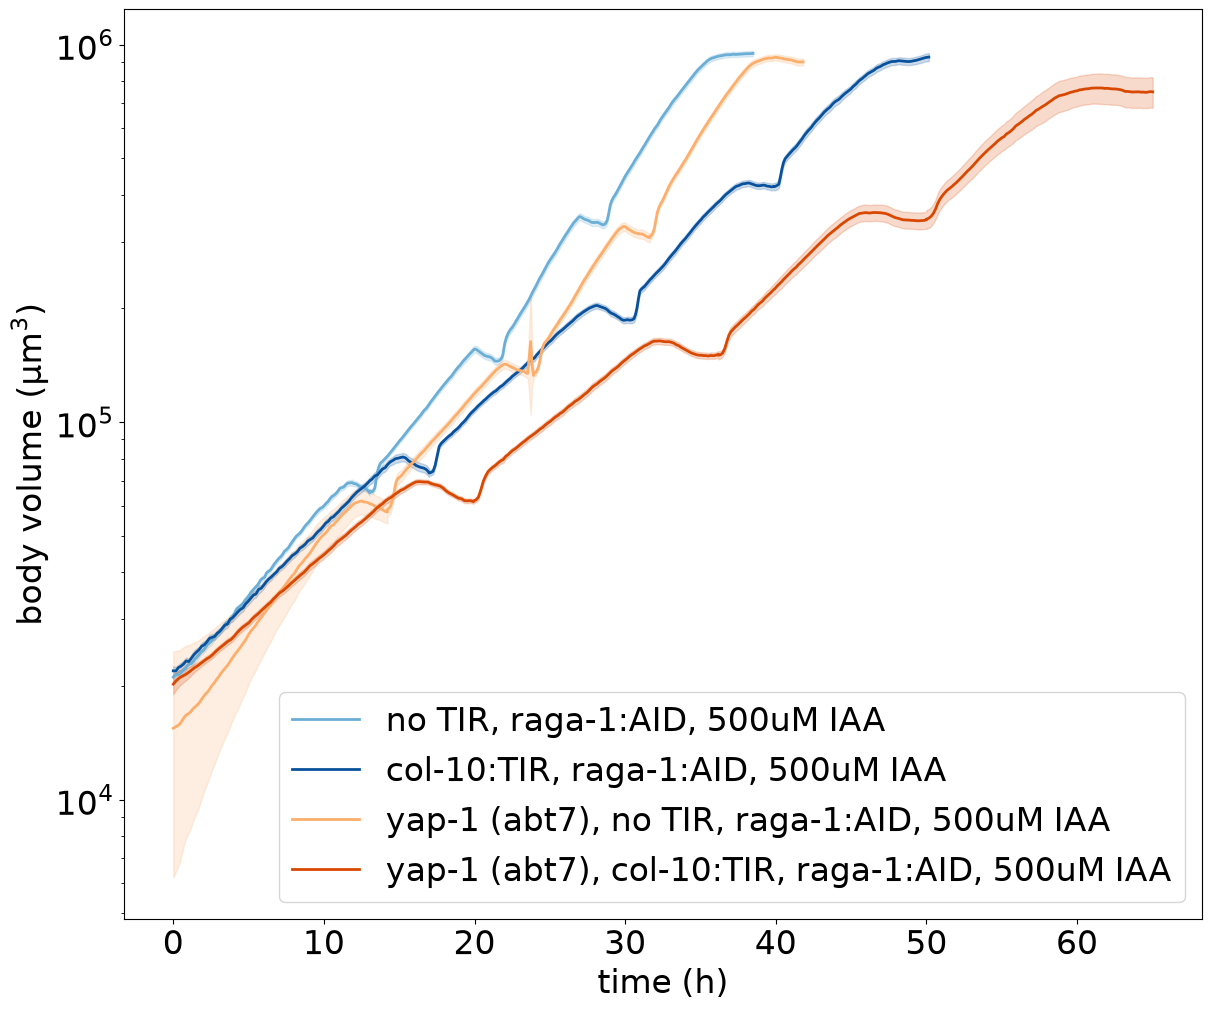

In [16]:
conditions_to_plot = [0, 1, 4, 5]

fig = plot_aggregated_series(
    conditions_struct,
    ["body_seg_str_volume"],
    conditions_to_plot,
    experiment_time=True,
    aggregation="mean",
    n_points=100,
    time_step=10,
    log_scale=True,
    colors=colors,
    legend={"description": ""},
    y_axis_label=r"body volume $(\mathrm{\mu m^3})$",
)

/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprec


Sample sizes (non-NaN) for event index 0, column 'larval_stage_durations_experiment_time_hours':
Condition 0: n=35
Condition 1: n=30
Condition 4: n=50
Condition 5: n=73
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 4: Mann-Whitney-Wilcoxon test two-sided, P_val:7.883e-03 U_stat=5.770e+02
1 vs. 5: Mann-Whitney-Wilcoxon test two-sided, P_val:6.448e-11 U_stat=1.945e+02


/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprec


Sample sizes (non-NaN) for event index 1, column 'larval_stage_durations_experiment_time_hours':
Condition 0: n=58
Condition 1: n=51
Condition 4: n=80
Condition 5: n=61
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.112e-08 U_stat=9.960e+02
1 vs. 5: Mann-Whitney-Wilcoxon test two-sided, P_val:6.312e-15 U_stat=2.205e+02


/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprec


Sample sizes (non-NaN) for event index 2, column 'larval_stage_durations_experiment_time_hours':
Condition 0: n=58
Condition 1: n=51
Condition 4: n=78
Condition 5: n=45
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.199e-12 U_stat=6.670e+02
1 vs. 5: Mann-Whitney-Wilcoxon test two-sided, P_val:8.238e-16 U_stat=5.100e+01


/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/home/spsalmon/micromamba/envs/align/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprec


Sample sizes (non-NaN) for event index 3, column 'larval_stage_durations_experiment_time_hours':
Condition 0: n=58
Condition 1: n=45
Condition 4: n=65
Condition 5: n=26
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.219e-02 U_stat=1.434e+03
1 vs. 5: Mann-Whitney-Wilcoxon test two-sided, P_val:1.071e-09 U_stat=7.400e+01


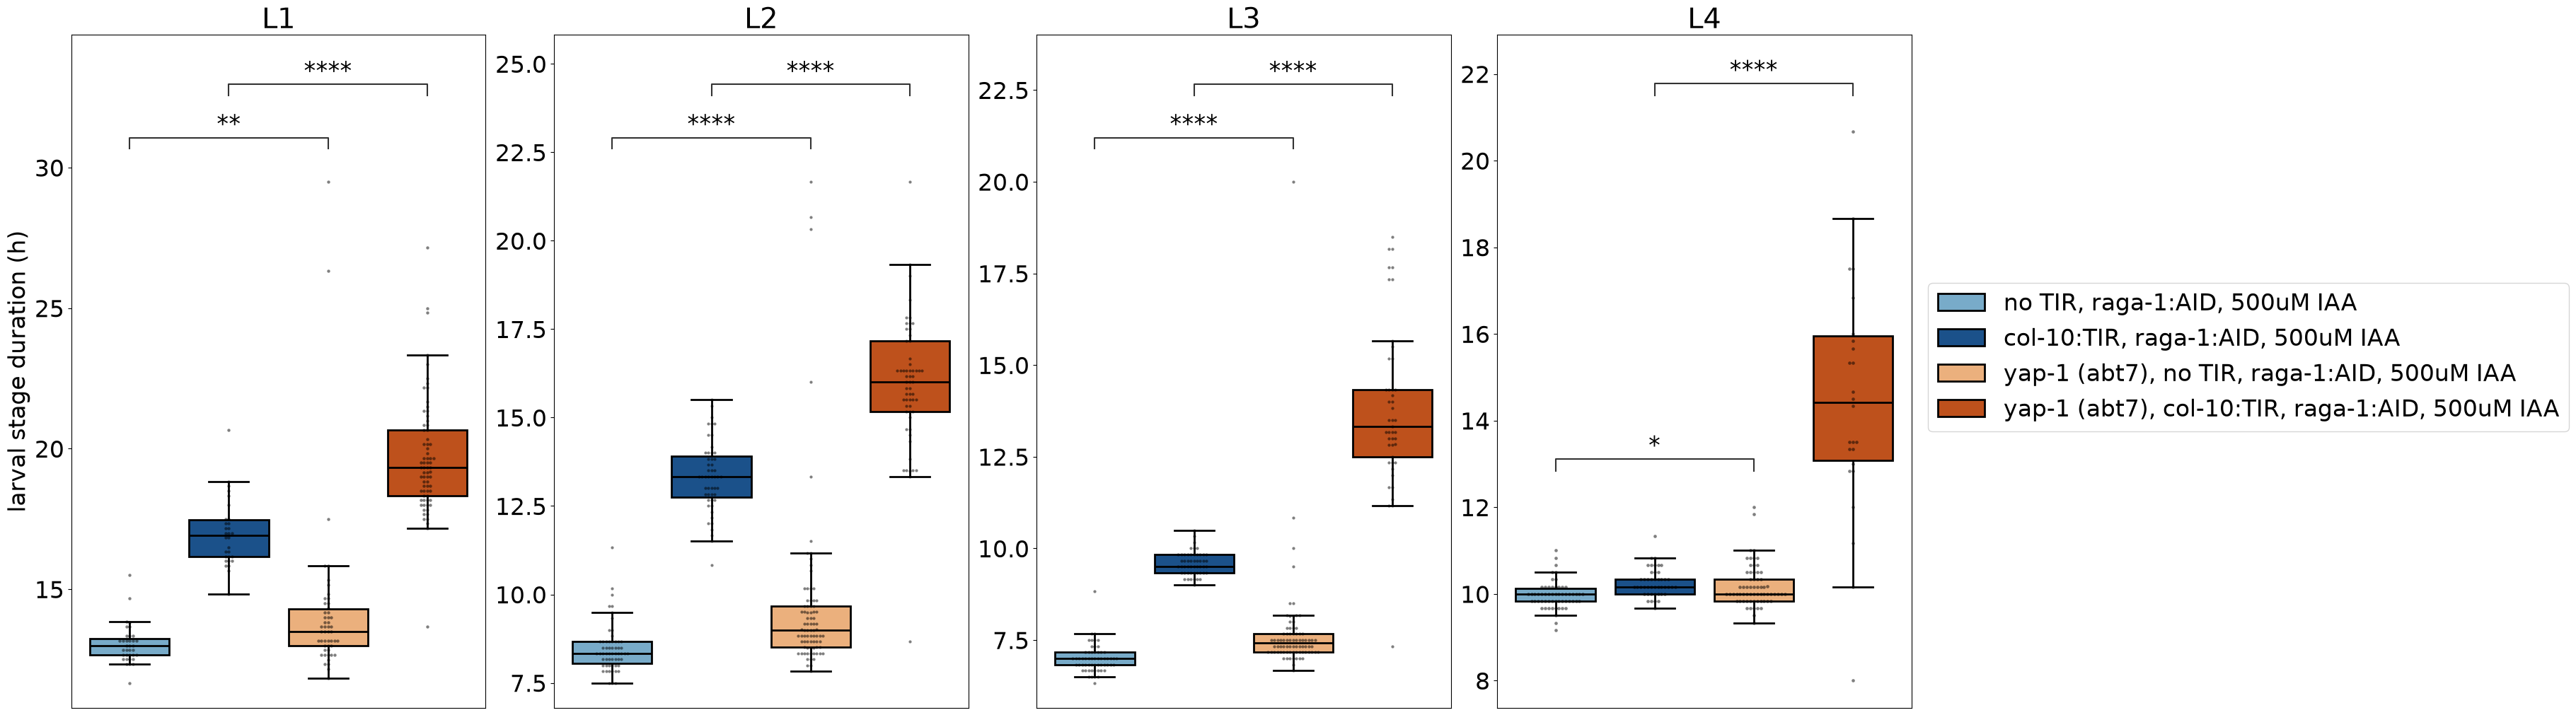

In [17]:
conditions_to_plot = [0, 1, 4, 5]
significance_pairs = [(0, 4), (1, 5)]
fig = boxplot(
    conditions_struct,
    "larval_stage_durations_experiment_time_hours",
    conditions_to_plot,
    colors=colors,
    share_y_axis=False,
    plot_significance=True,
    significance_pairs=significance_pairs,
    log_scale=False,
    legend={"description": ""},
    y_axis_label="larval stage duration (h)",
    titles=["L1", "L2", "L3", "L4"],
)

# yap-1 mutation causes dumpiness, amplified by epidermal growth inhibition

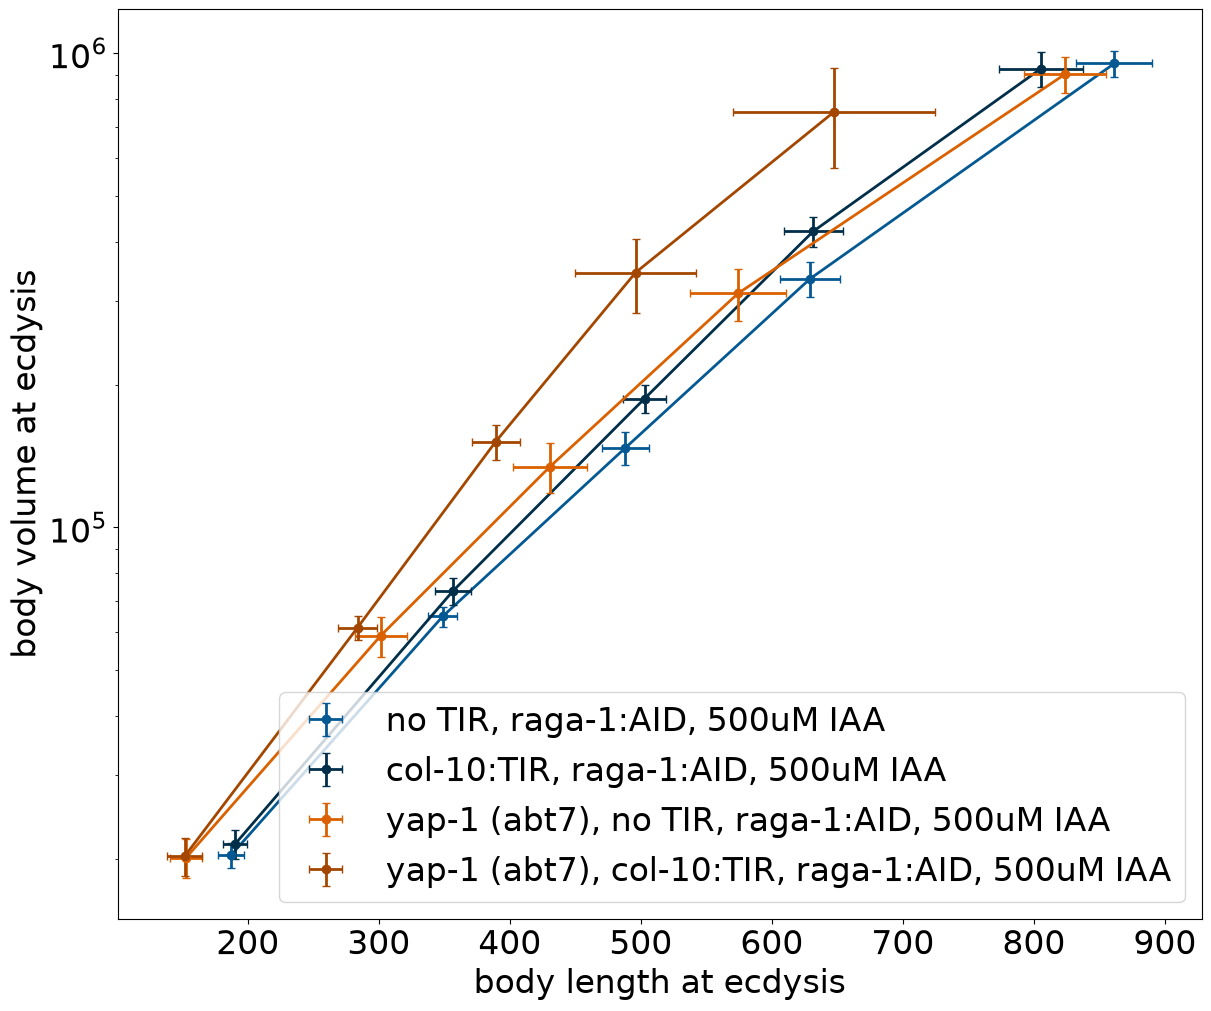

In [11]:
fig = plot_correlation_at_ecdysis(
    conditions_struct,
    "body_seg_str_length_at_ecdysis",
    "body_seg_str_volume_at_ecdysis",
    conditions_to_plot,
    remove_hatch=False,
    colors=colors,
    log_scale=(False, True),
    legend={"description": ""},
    y_axis_label="body volume at ecdysis",
    x_axis_label="body length at ecdysis",
)

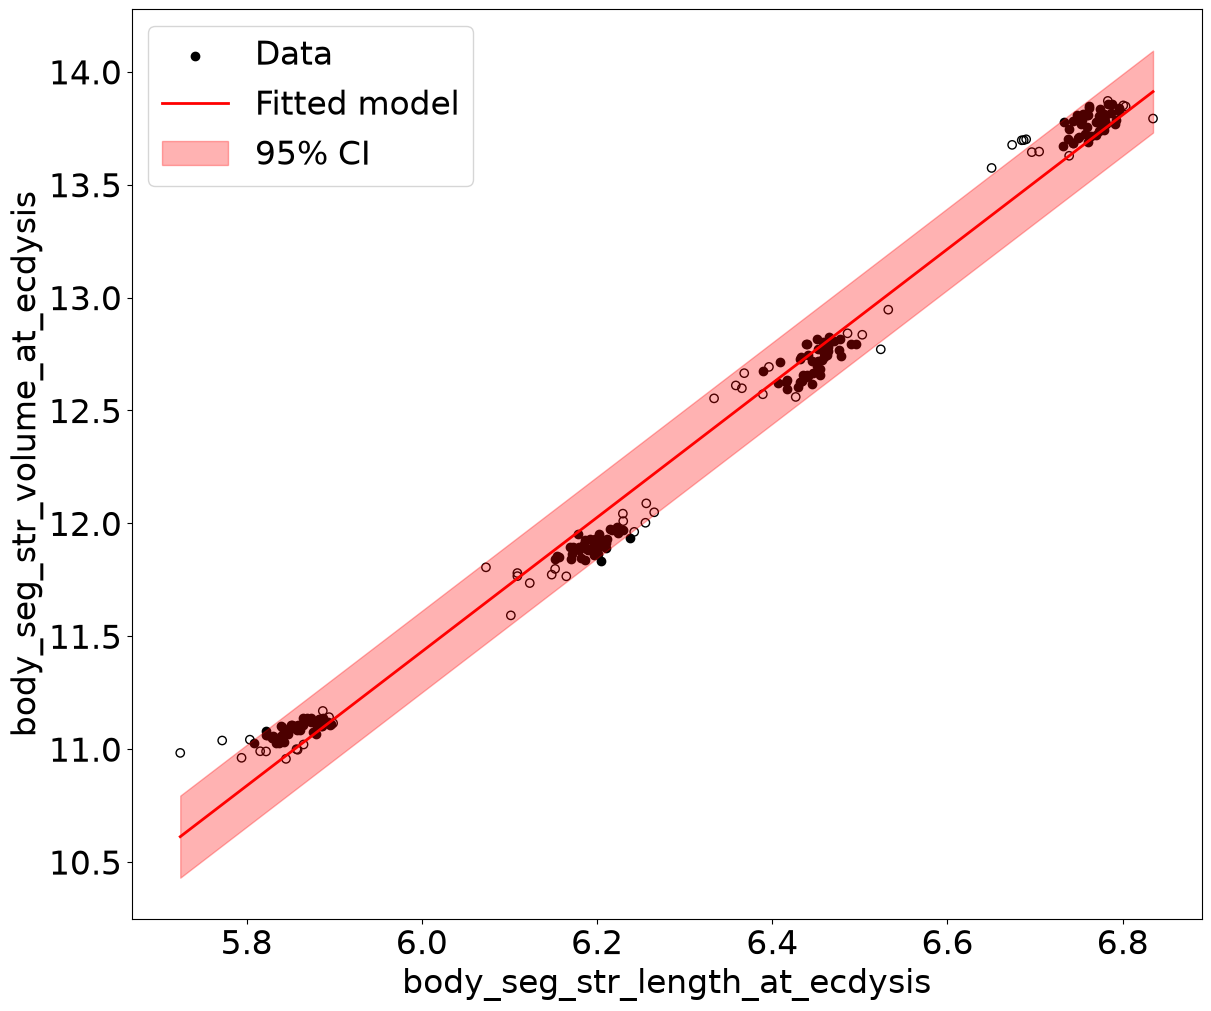

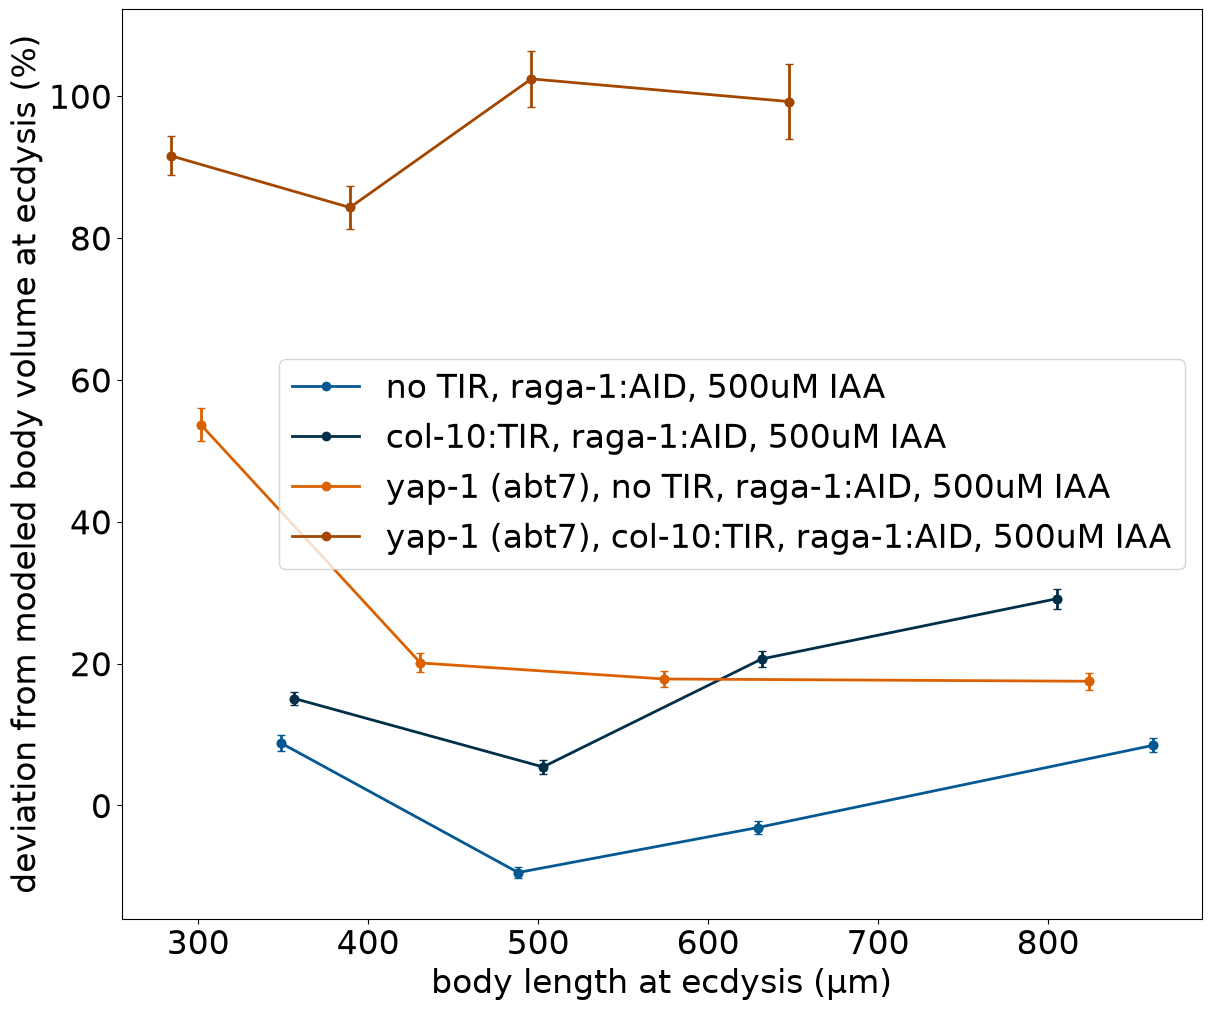

In [12]:
control_condition = 0
fig = plot_deviation_from_model_at_ecdysis(
    conditions_struct,
    "body_seg_str_length_at_ecdysis",
    "body_seg_str_volume_at_ecdysis",
    control_condition,
    conditions_to_plot,
    colors=colors,
    remove_hatch=True,
    log_scale=False,
    legend={"description": ""},
    x_axis_label="body length at ecdysis (µm)",
    y_axis_label="deviation from modeled body volume at ecdysis (%)",
    poly_degree=1,
)

# yap-1 mutation causes pharynx dumpiness, amplified by epidermal growth inhibition

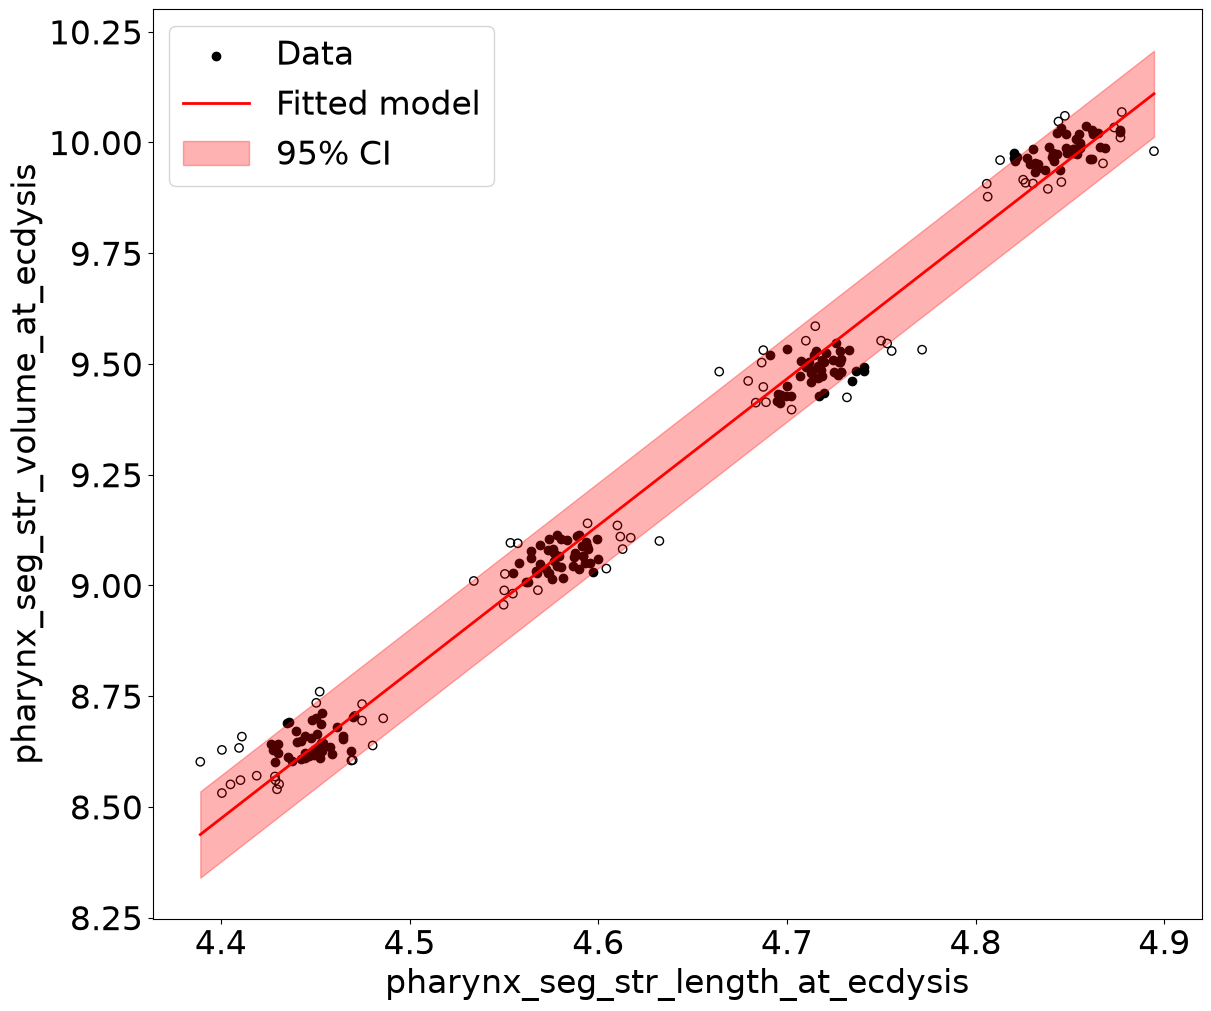

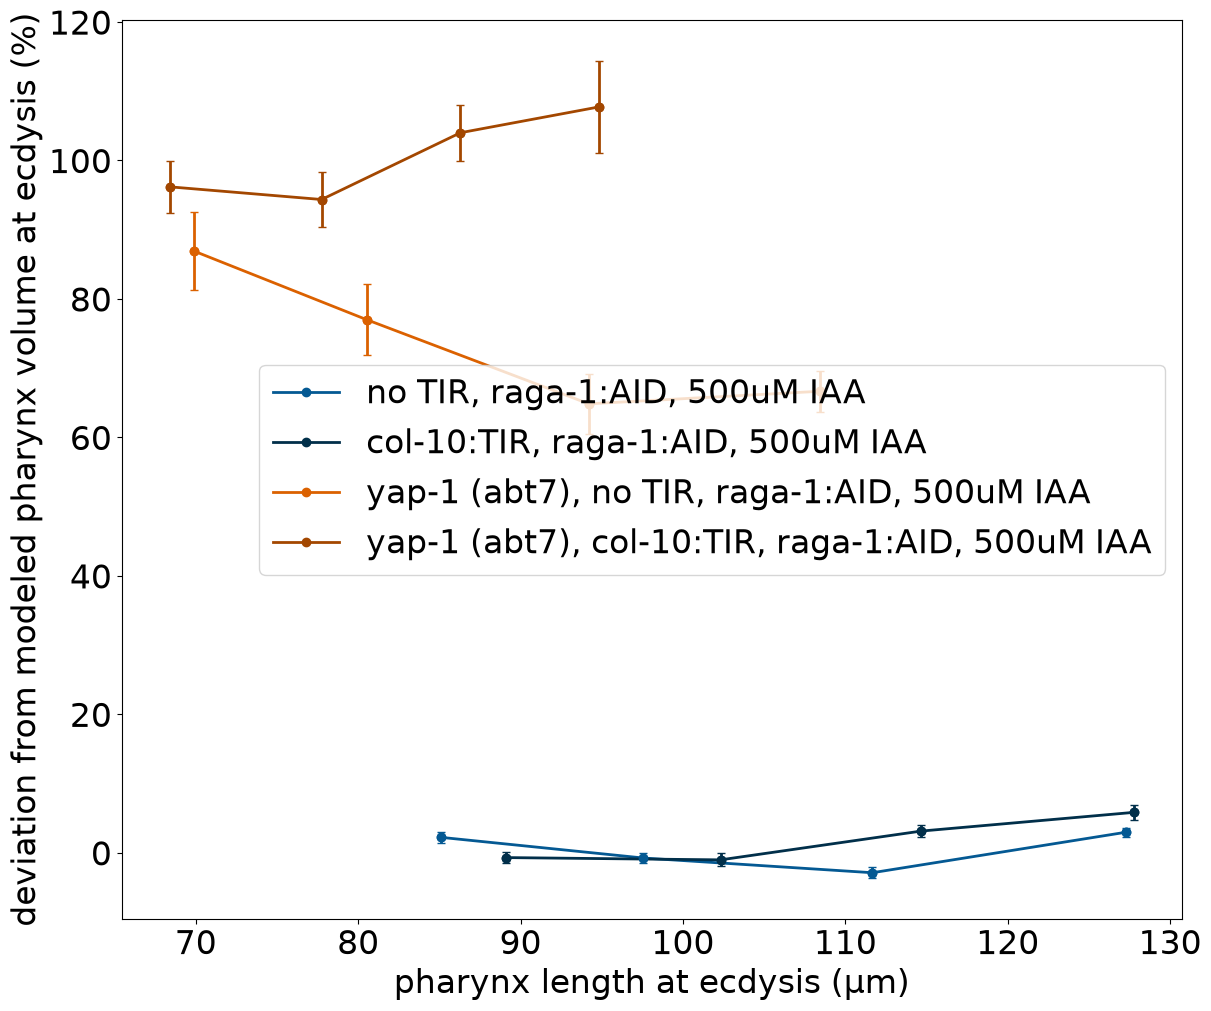

In [13]:
control_condition = 0
fig = plot_deviation_from_model_at_ecdysis(
    conditions_struct,
    "pharynx_seg_str_length_at_ecdysis",
    "pharynx_seg_str_volume_at_ecdysis",
    control_condition,
    conditions_to_plot,
    colors=colors,
    remove_hatch=True,
    log_scale=False,
    legend={"description": ""},
    x_axis_label="pharynx length at ecdysis (µm)",
    y_axis_label="deviation from modeled pharynx volume at ecdysis (%)",
    poly_degree=1,
)

# yap-1 is necessary to maintain proper pharynx to body proportions under epidermal growth inhibition

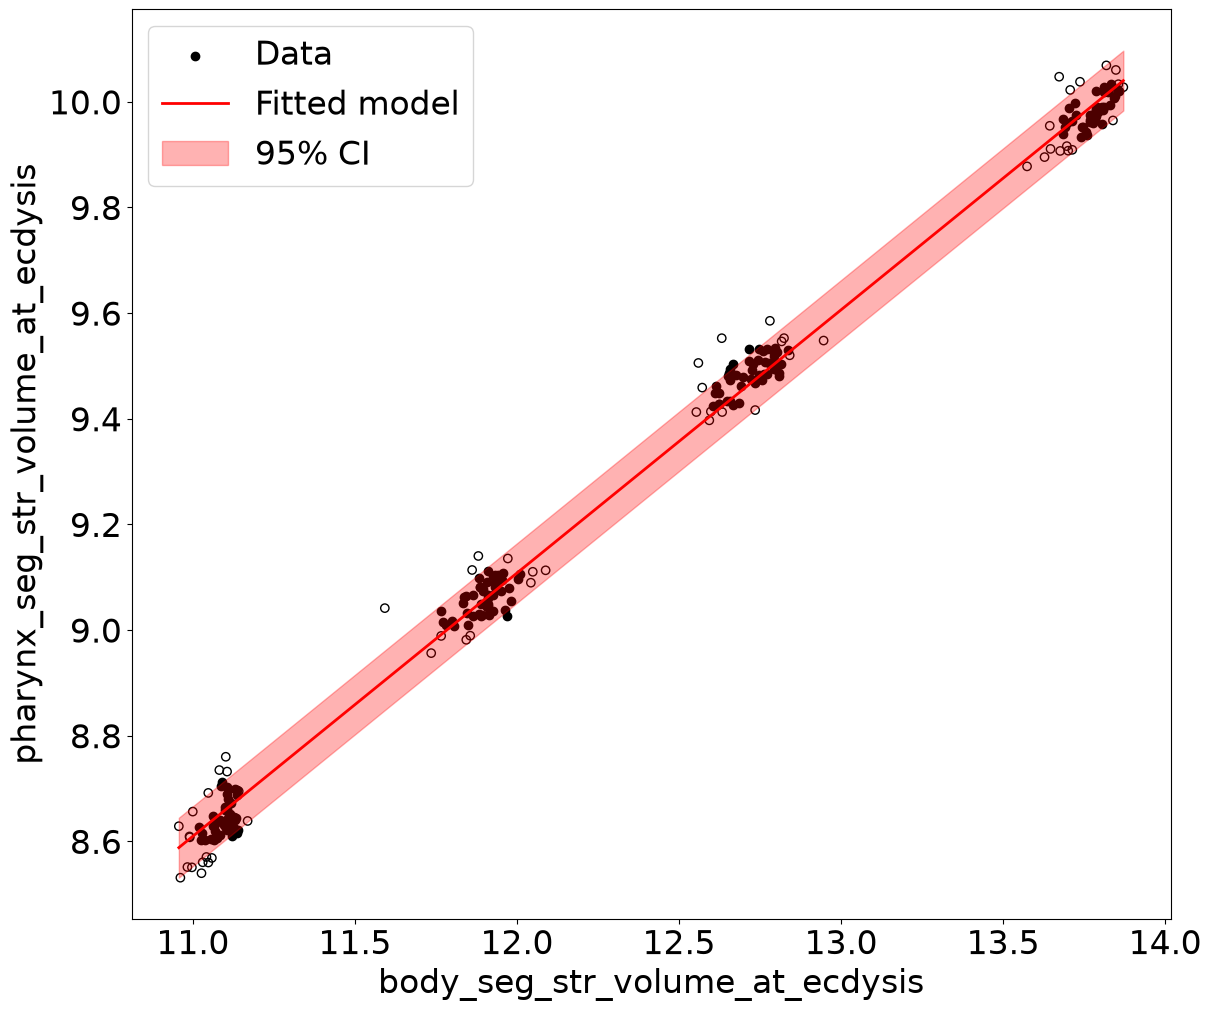

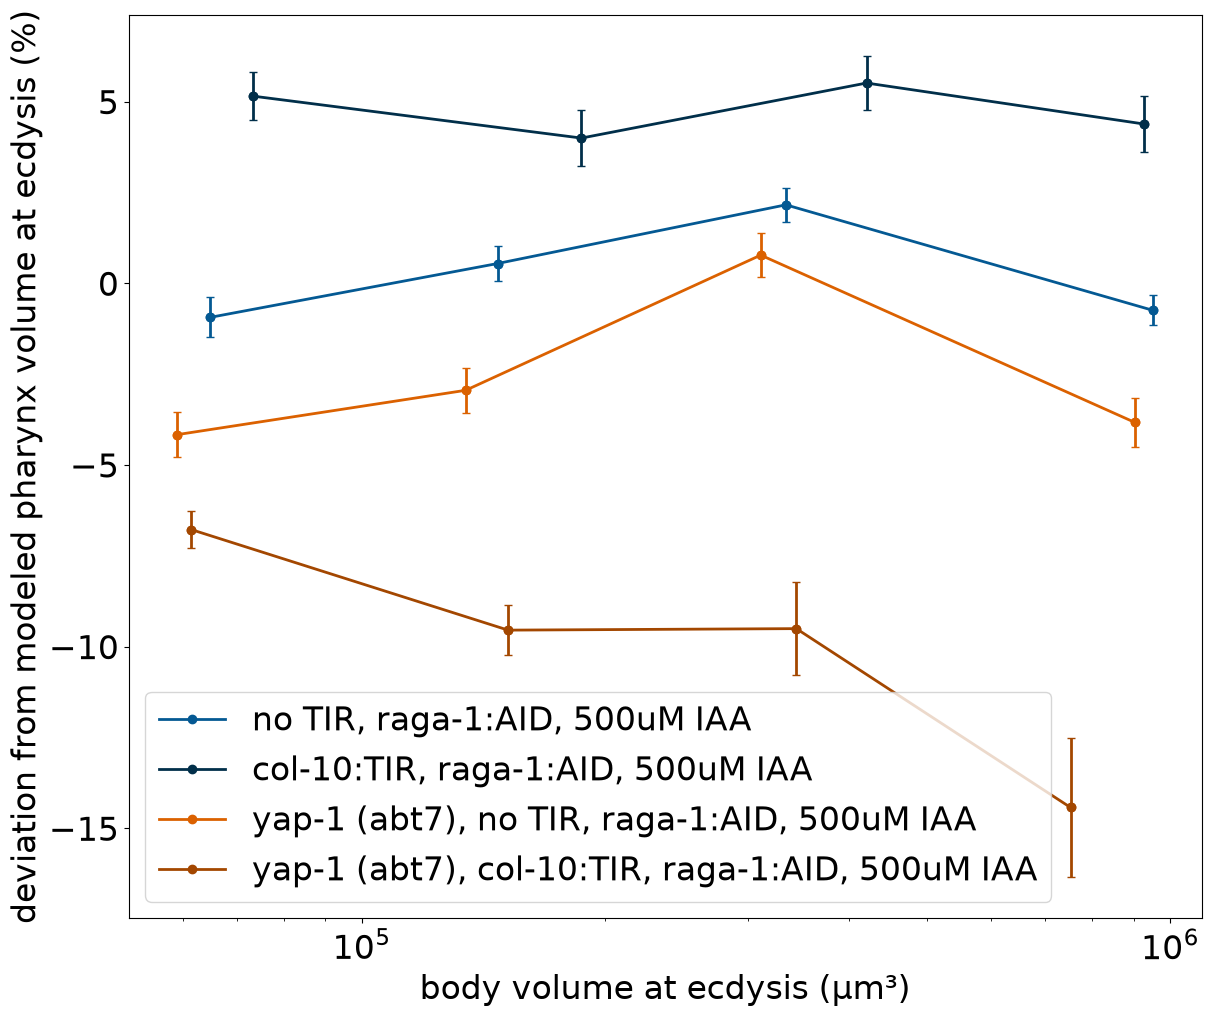

In [14]:
control_condition = 0
fig = plot_deviation_from_model_at_ecdysis(
    conditions_struct,
    "body_seg_str_volume_at_ecdysis",
    "pharynx_seg_str_volume_at_ecdysis",
    control_condition,
    conditions_to_plot,
    colors=colors,
    remove_hatch=True,
    log_scale=(True, False),
    legend={"description": ""},
    x_axis_label="body volume at ecdysis (µm³)",
    y_axis_label="deviation from modeled pharynx volume at ecdysis (%)",
    poly_degree=1,
)